# Instagram Content Performance Analysis (Python)

**Goal:** find out which post type, posting time, hashtag count and niche give the best reach and engagement.

> Data note: `instagram_raw.csv` is a **synthetic proxy dataset** (2,000 posts, 60 accounts, 2025), so the findings are for practice, not real-world conclusions.

**Engagement rate** = (likes + comments + shares + saves) / reach

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

## 1. Load and inspect

In [2]:
df = pd.read_csv("../data/instagram_raw.csv")
print("Shape:", df.shape)
df.head()

Shape: (2015, 18)

  post_id account_id      niche  ...  saves profile_visits follows_gained
0  P00808   acct_045    Fitness  ...  452.0           1197            322
1  P01448   acct_024    Fashion  ...  208.0            321             89
2  P01992   acct_028  Education  ...   84.0            213             35
3  P01817   acct_015     Travel  ...   36.0            139             26
4  P00664   acct_034  Education  ...   87.0             38              7

[5 rows x 18 columns]

In [3]:
print("Duplicate rows:", df.duplicated().sum())
print()
print("Missing values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

Duplicate rows: 15

Missing values:
caption_length    20
saves             20
dtype: int64

## 2. Clean
Remove duplicates and fill the missing `saves` and `caption_length` values with the median.

In [4]:
df = df.drop_duplicates()
df["saves"] = df["saves"].fillna(df["saves"].median())
df["caption_length"] = df["caption_length"].fillna(df["caption_length"].median())
print("Clean shape:", df.shape)
print("Missing values left:", df.isnull().sum().sum())

Clean shape: (2000, 18)
Missing values left: 0

## 3. Feature engineering

In [5]:
df["post_date"] = pd.to_datetime(df["post_date"])
df["hour"] = pd.to_datetime(df["post_time"], format="%H:%M").dt.hour
df["weekday"] = df["post_date"].dt.day_name()
df["month"] = df["post_date"].dt.month_name()
df["month_num"] = df["post_date"].dt.month
df["engagement_rate"] = (df.likes + df.comments + df.shares + df.saves) / df.reach
df["time_slot"] = pd.cut(df["hour"], bins=[-1, 5, 11, 17, 23],
                         labels=["Late night (0-5)", "Morning (6-11)", "Afternoon (12-17)", "Evening (18-23)"])
df["hashtag_group"] = pd.cut(df["hashtag_count"], bins=[-1, 5, 10, 15, 30], labels=["0-5", "6-10", "11-15", "16+"])
df[["post_type", "hour", "weekday", "reach", "engagement_rate", "time_slot"]].head()

  post_type  hour weekday  reach  engagement_rate          time_slot
0  Carousel    10  Sunday  62990         0.057660     Morning (6-11)
1      Reel    12  Monday  13997         0.080660  Afternoon (12-17)
2     Image     8  Monday  26200         0.074504     Morning (6-11)
3     Image    12  Monday  12708         0.065628  Afternoon (12-17)
4  Carousel    20  Sunday   3153         0.126546    Evening (18-23)

## 4. Which post type performs best?

           engagement_rate      reach
post_type                            
Reel                 0.102  43576.183
Carousel             0.085  25340.249
Video                0.081  24574.404
Image                0.080  18606.567

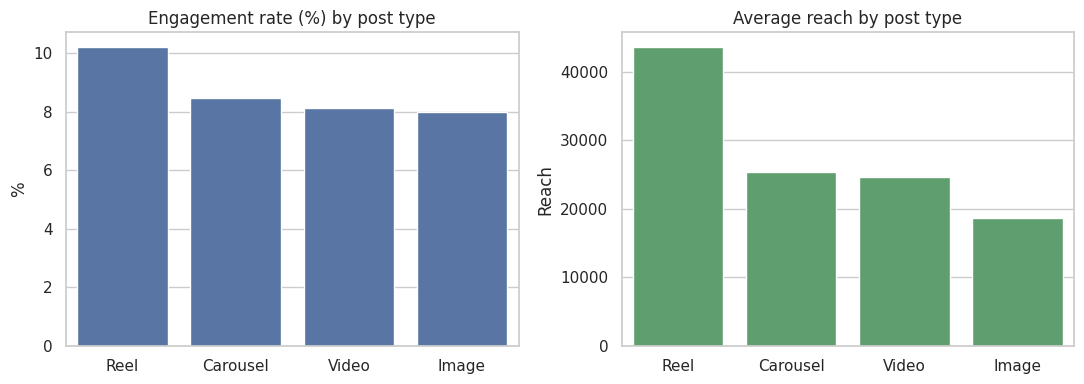

In [6]:
by_type = df.groupby("post_type")[["engagement_rate", "reach"]].mean().sort_values("reach", ascending=False)
print(by_type.round(3))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.barplot(x=by_type.index, y=by_type["engagement_rate"] * 100, ax=ax[0], color="#4C72B0")
ax[0].set_title("Engagement rate (%) by post type"); ax[0].set_xlabel(""); ax[0].set_ylabel("%")
sns.barplot(x=by_type.index, y=by_type["reach"], ax=ax[1], color="#55A868")
ax[1].set_title("Average reach by post type"); ax[1].set_xlabel(""); ax[1].set_ylabel("Reach")
plt.tight_layout(); plt.show()

## 5. When should we post?

In [7]:
by_slot = df.groupby("time_slot", observed=True)["reach"].mean()
print(by_slot.round(0))
print()
print("Top 5 hours by average reach:")
print(df.groupby("hour")["reach"].mean().sort_values(ascending=False).head(5).round(0))

time_slot
Late night (0-5)     18179.0
Morning (6-11)       31143.0
Afternoon (12-17)    29143.0
Evening (18-23)      39533.0
Name: reach, dtype: float64

Top 5 hours by average reach:
hour
18    46605.0
19    45726.0
22    42642.0
21    39079.0
20    38548.0
Name: reach, dtype: float64

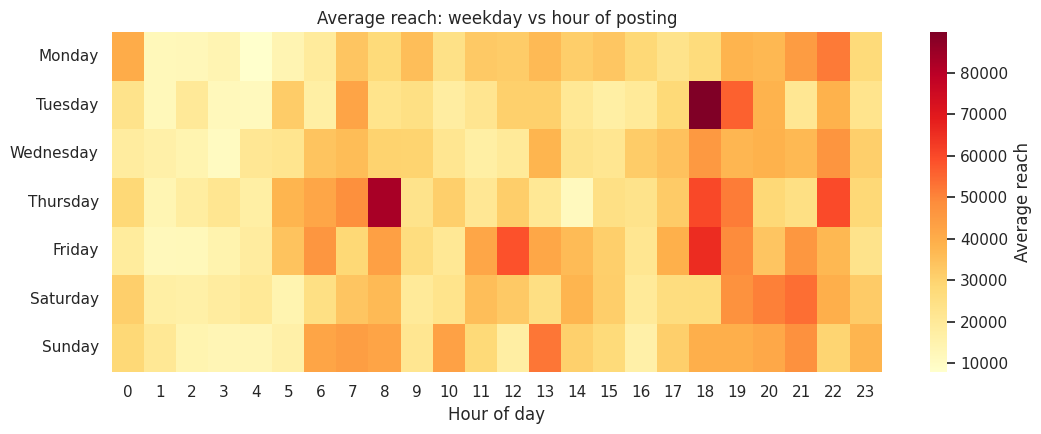

In [8]:
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
heat = df.pivot_table(index="weekday", columns="hour", values="reach", aggfunc="mean").reindex(order)
plt.figure(figsize=(11, 4.5))
sns.heatmap(heat, cmap="YlOrRd", cbar_kws={"label": "Average reach"})
plt.title("Average reach: weekday vs hour of posting"); plt.xlabel("Hour of day"); plt.ylabel("")
plt.tight_layout(); plt.show()

## 6. Do hashtags and call-to-actions (CTA) help?

In [9]:
print("Hashtag groups:")
print(df.groupby("hashtag_group", observed=True)[["reach", "engagement_rate"]].mean().round(3))
print()
print("CTA (0 = no, 1 = yes):")
print(df.groupby("has_cta")[["reach", "engagement_rate"]].mean().round(3))

Hashtag groups:
                   reach  engagement_rate
hashtag_group                            
0-5            24402.693            0.090
6-10           29120.292            0.088
11-15          31170.462            0.090
16+            31061.365            0.089

CTA (0 = no, 1 = yes):
             reach  engagement_rate
has_cta                            
0        29191.346            0.090
1        30214.831            0.088

## 7. Niche performance

           engagement_rate      reach
niche                                
Comedy               0.088  51116.387
Fitness              0.091  37833.137
Travel               0.085  30835.051
Tech                 0.091  29337.102
Education            0.086  29078.620
Fashion              0.090  25781.931
Beauty               0.089  24195.489
Food                 0.092  19381.774

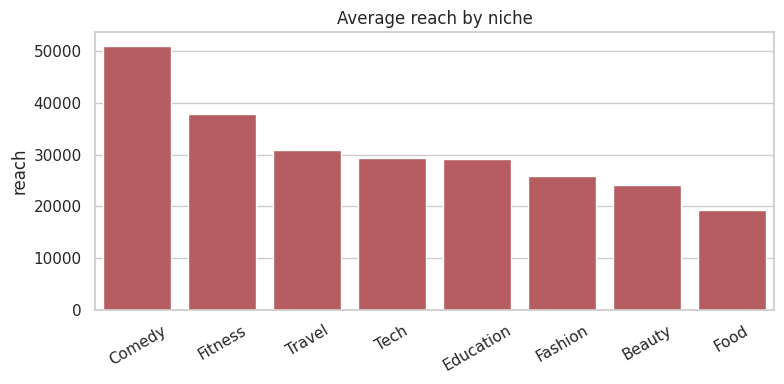

In [10]:
by_niche = df.groupby("niche")[["engagement_rate", "reach"]].mean().sort_values("reach", ascending=False)
print(by_niche.round(3))

plt.figure(figsize=(8, 4))
sns.barplot(x=by_niche.index, y=by_niche["reach"], color="#C44E52")
plt.title("Average reach by niche"); plt.xlabel(""); plt.xticks(rotation=30)
plt.tight_layout(); plt.show()

## 8. Monthly trend

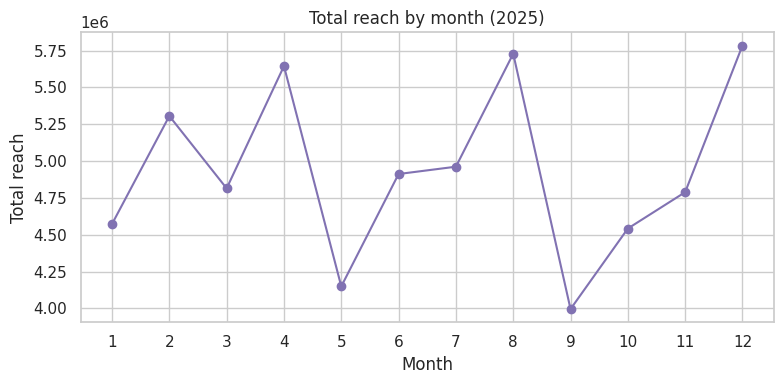

In [11]:
monthly = df.groupby("month_num")["reach"].sum()
plt.figure(figsize=(8, 4))
plt.plot(monthly.index, monthly.values, marker="o", color="#8172B2")
plt.xticks(range(1, 13)); plt.title("Total reach by month (2025)"); plt.xlabel("Month"); plt.ylabel("Total reach")
plt.tight_layout(); plt.show()

## 9. What is correlated with reach?

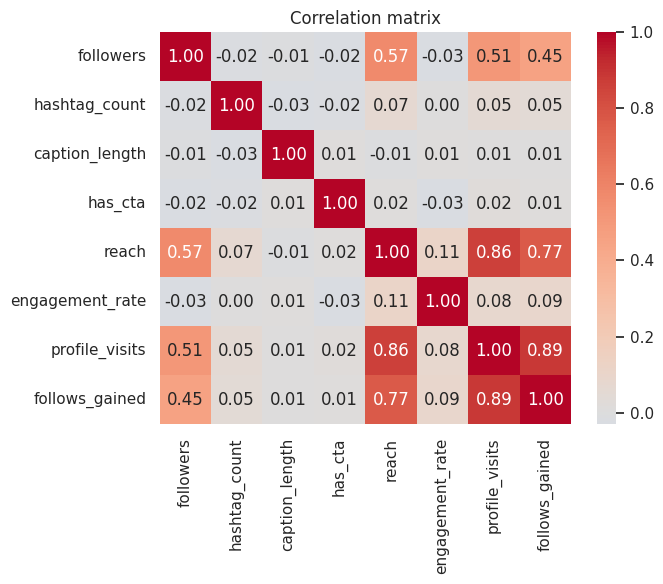

In [12]:
cols = ["followers", "hashtag_count", "caption_length", "has_cta", "reach", "engagement_rate", "profile_visits", "follows_gained"]
corr = df[cols].corr()
plt.figure(figsize=(7, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix"); plt.tight_layout(); plt.show()

## 10. Save the clean data

In [13]:
out = df.drop(columns=["time_slot", "hashtag_group"]).copy()
out["post_date"] = out["post_date"].dt.strftime("%Y-%m-%d")
out.to_csv("../data/instagram_clean.csv", index=False)
print("Saved ../data/instagram_clean.csv with", len(out), "rows")

Saved ../data/instagram_clean.csv with 2000 rows

## 11. Key insights (from this synthetic dataset)

1. **Reels win.** They have the highest engagement rate (about 10.2%, versus about 8.0% for images) and about 2.3x the average reach of images.
2. **Evenings are the best time.** Posts at 18:00-23:59 average the highest reach, and 18:00-19:00 are the strongest hours. Late-night posts (0-5) do worst.
3. **Hashtags help up to a point.** Reach rises from the 0-5 group to the 11-15 group, then flattens, so more than 15 hashtags adds little.
4. **CTAs make little difference** here: reach is about 3% higher, and engagement rate is slightly lower.
5. **Niche matters for reach, not engagement rate.** Comedy has by far the highest reach, while engagement rates across niches are almost the same.
6. **More followers means more reach, not better engagement.** Followers correlate with reach (about 0.57) but not with engagement rate.

**Recommendation:** post Reels in the evening with around 10-15 hashtags.